In [ ]:
import anndata
import gc
import geopandas as gpd
import json
import numpy as np
import matplotlib.patches as patches
import matplotlib.pyplot as plt
import os
import pandas as pd
from pathlib import Path
import scanpy as sc
from scipy import sparse
from shapely.geometry import box
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score, homogeneity_score, completeness_score, v_measure_score

%run functions.ipynb

# Histology

### UNI Model

In [ ]:
# Basic variables
sample = "CRC_P2"
bin_size = "002um"
pred_col = "leiden_0.2" # cluster resolution
patch_size = 224

# Paths
basedir = Path("../data/")
dir_sample = basedir / sample
dir_base_output = dir_sample / f"output/binned_outputs/square_{bin_size}"
dir_histology = dir_sample / "01_preprocessing/unimodel"
dir_ground_truth = dir_sample / "ground_truth"

# Files
adata_filtered_bins = sc.read_h5ad(dir_histology / "filtered_WSI_patch_embeddings.h5ad")
adata_filtered_bins = adata_filtered_bins[adata_filtered_bins.obs["Slide_ID"] == sample]

# Extract needed info
df = adata_filtered_bins.obs[["Slide_ID", "X", "Y", pred_col]].copy()

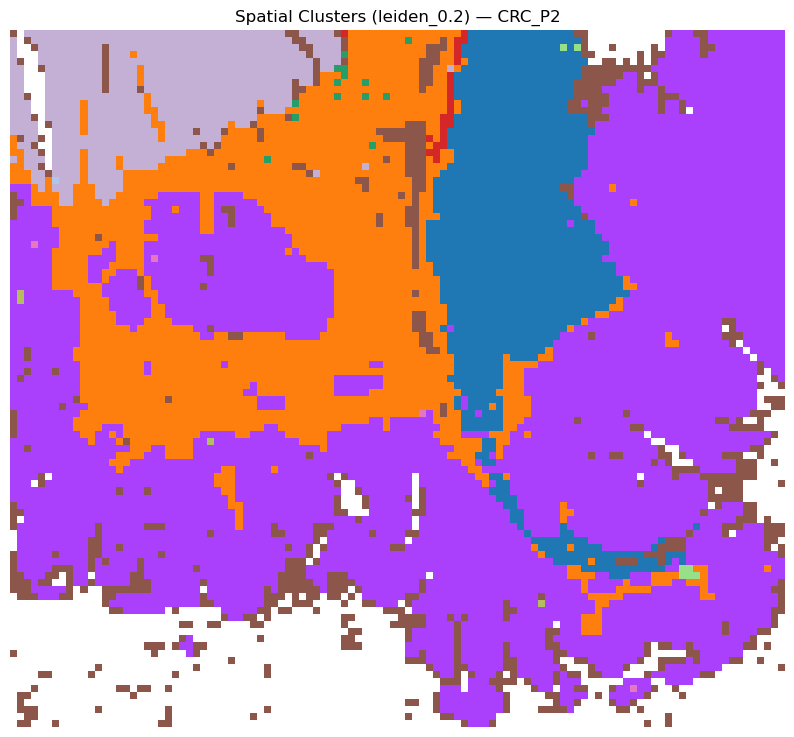

In [ ]:
if f"{pred_col}_colors" in adata_filtered_bins.uns:
    pred_df = sorted(df[pred_col].unique(), key=lambda x: int(x))
    colors = adata_filtered_bins.uns[f"{pred_col}_colors"]
    color_map = {c: colors[i % len(colors)] for i, c in enumerate(pred_df)}
else:
    unique_clusters = df[pred_col].unique()
    cmap = cm.get_cmap("tab20", len(unique_clusters))
    color_map = {c: cmap(i) for i, c in enumerate(unique_clusters)}

# Create figure
fig, ax = plt.subplots(figsize=(10, 10))
ax.set_aspect('equal')
ax.set_title(f"Spatial Clusters ({pred_col}) — {sample}")

# Draw each patch as a colored rectangle
for _, row in df.iterrows():
    x, y = row["X"], row["Y"]
    color = color_map[row[pred_col]]
    rect = patches.Rectangle(
        (x, y), patch_size, patch_size,
        facecolor=color, edgecolor='none'
    )
    ax.add_patch(rect)

# Set coordinate system: top-left = (0,0)
ax.set_xlim(df["X"].min(), df["X"].max() + patch_size)
ax.set_ylim(df["Y"].min() + patch_size, df["Y"].max())
ax.axis("off")

plt.show()

**Comparing with ground truth**  
Since this case deals with patches, but the ground truth is based on bins, we will first assign each bin to a patch.

Then we will evaluate.

In [ ]:
truth_df = pd.read_csv((dir_ground_truth / "2um_squares_annotation.csv"), 
                                        delimiter='\t', header=None, names=['barcode', 'tissuetype'])
tissue_positions = pd.read_parquet(dir_base_output / "spatial/tissue_positions.parquet")
truth_df = pd.merge(truth_df, tissue_positions, on='barcode', how='left')

scalefactor_path = dir_base_output / "spatial/scalefactors_json.json"

bin_cols = ['Patch_ID', 'leiden_0.2', 'leiden_0.5', 'leiden_1.0', 'leiden_2.0']
patch_cols = ['barcode', 'tissuetype', 'in_tissue']
matched_df = assign_bins_to_patches(truth_df, adata_filtered_bins.obs, bin_cols, patch_cols, 'barcode', 
                                    scalefactor_path, dir_ground_truth, 224)

In [ ]:
matched_df = pd.read_parquet(dir_ground_truth / "bin_patch_clusters.parquet")

y_true = matched_df['tissuetype']
y_pred = matched_df['leiden_0.2']

results = {
    'Adjusted Rand Index': adjusted_rand_score(y_true, y_pred),
    'Normalized Mutual Info': normalized_mutual_info_score(y_true, y_pred),
    'Homogeneity': homogeneity_score(y_true, y_pred),
    'Completeness': completeness_score(y_true, y_pred),
    'V-Measure': v_measure_score(y_true, y_pred)
}

for k, v in results.items():
    print(f"{k}: {v:.3f}")


Adjusted Rand Index: 0.772
Normalized Mutual Info: 0.687
Homogeneity: 0.728
Completeness: 0.650
V-Measure: 0.687


# Transcriptomics

In [ ]:
# Basic variables
sample = "CRC_P2"
bin_size = "002um"
dir_cellseg = "cell_seg_stardist"

# BBasic paths
basedir = Path("../data/")
dir_sample = basedir / sample
dir_base_input = dir_sample / "input"
dir_base_output = dir_sample / f"output/binned_outputs/square_{bin_size}"
dir_custom_binning = dir_sample / "01_preprocessing" / dir_cellseg / bin_size /  "custom_binning"
dir_ground_truth = dir_sample / "ground_truth"
dir_histology = dir_sample / "01_preprocessing/unimodel/metadata"

### For aggregated bin size 004um: 
We load the filtered feature matrix and assign each bin to a larger 4x4um bin. 
This information is stored in the same dataframe. 
 
We then ...

In [ ]:
adata_filtered_bins = sc.read_10x_h5(os.path.join(dir_base_output, "filtered_feature_bc_matrix.h5"))

# Load Spatial Coordinates
f_tissue_positions = dir_base_output+'/spatial/tissue_positions.parquet'
df_tissue_positions=pd.read_parquet(f_tissue_positions)

#Set the index of the dataframe to the barcodes
df_tissue_positions = df_tissue_positions.set_index('barcode')

# Create an index in the dataframe to check joins
df_tissue_positions['index']=df_tissue_positions.index

# Adding the tissue positions to the meta data
adata_filtered_bins.obs = pd.merge(adata_filtered_bins.obs, df_tissue_positions, left_index=True, right_index=True)

/home/charlottewolf/miniconda3/envs/NucleiSeg/lib/python3.11/site-packages/anndata/_core/anndata.py:1820: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/home/charlottewolf/miniconda3/envs/NucleiSeg/lib/python3.11/site-packages/anndata/_core/anndata.py:1820: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


In [4]:
# Params
super_bin_size = 8  # size of large bin in µm (must be even)
small_bin_size = 2  # size of original small bins in µm
scale_factor = super_bin_size // small_bin_size  # number of small bins per large bin side

In [5]:
array_size = adata_filtered_bins.obs["array_col"].max()
print("Total bin count for 2x2um BEFORE filtering: ", array_size**2)
print("Bin count for 2x2um bins AFTER filtering: ", adata_filtered_bins.obs.shape[0])

adata_filtered_bins.obs['large_x'] = adata_filtered_bins.obs['array_col'] // scale_factor
adata_filtered_bins.obs['large_y'] = adata_filtered_bins.obs['array_row'] // scale_factor

# Count small bins per candidate large bin
counts = (
    adata_filtered_bins.obs
    .groupby(['large_x', 'large_y'])
    .size()
    .reset_index(name='n_bins')
)

bin_id = f'{super_bin_size}x{super_bin_size}um_bin_id'

full_bins = counts[counts['n_bins'] == scale_factor**2][['large_x', 'large_y']].copy()
full_bins[bin_id] = range(len(full_bins))
mapping = full_bins.set_index(['large_x', 'large_y'])[bin_id]
adata_filtered_bins.obs[bin_id] = list(zip(adata_filtered_bins.obs['large_x'], adata_filtered_bins.obs['large_y']))

adata_filtered_bins.obs[bin_id] = adata_filtered_bins.obs[bin_id].map(mapping)
#adata_filtered_bins.obs.drop(columns=['large_x', 'large_y'], inplace=True)

print(f"Bin count for complete {super_bin_size}x{super_bin_size}um bins: ", 
      adata_filtered_bins.obs[bin_id].unique().shape[0])

# Optionally for storage optimisation
del df_tissue_positions, counts, full_bins, mapping
gc.collect()

Total bin count for 2x2um BEFORE filtering:  11215801
Bin count for 2x2um bins AFTER filtering:  8731400
Bin count for complete 8x8um bins:  545513


31

**Preprocessing.**  
We now plot the UMI distribution.
The goal is to select a cut off and filter out low-quality bins.

In [6]:
bin_series = adata_filtered_bins.obs[bin_id]       # column with large-bin IDs
group_labels = bin_series.to_numpy()

# Get unique large-bin IDs and assignment for each small-bin row
unique_groups, inverse = np.unique(group_labels, return_inverse=True)

N_groups = len(unique_groups)
N_cells = adata_filtered_bins.n_obs

print(f"Number of small bins (rows): {N_cells}")
print(f"Number of large bins (groups): {N_groups}")

# Build sparse assignment matrix M (groups × cells)
M = sparse.csr_matrix(
    (np.ones(N_cells, dtype=np.int8), (inverse, np.arange(N_cells))),
    shape=(N_groups, N_cells)
)

print("Summing counts using sparse matrix multiplication...")
summed_counts = M @ adata_filtered_bins.X      # -> shape: (N_groups × N_genes)

coords_df = adata_filtered_bins.obs[[bin_id, "large_x", "large_y"]].copy()
grouped_coords = coords_df.groupby(bin_id)[["large_x", "large_y"]].first()
obs_df = grouped_coords.reindex(unique_groups)

grouped_filtered_adata = anndata.AnnData(
    X=summed_counts,
    obs=obs_df,
    var=adata_filtered_bins.var
)

# Optional cleanup
del M, group_labels, inverse, summed_counts, obs_df, grouped_coords, coords_df
gc.collect()

Number of small bins (rows): 8731400
Number of large bins (groups): 545513
Summing counts using sparse matrix multiplication...


/home/charlottewolf/miniconda3/envs/NucleiSeg/lib/python3.11/site-packages/anndata/_core/aligned_df.py:67: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)
/home/charlottewolf/miniconda3/envs/NucleiSeg/lib/python3.11/site-packages/anndata/_core/anndata.py:1820: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


0

In [ ]:
# Group the data by unique bin IDs
# This is the original version by 10x. 
# I used matrix multiplication and Vectorized Grouped Summation for AnnData instead, speeding up the process and saving RAM.
# See cell above.
'''groupby_object = adata_filtered_bins.obs.groupby([bin_id], observed=True)
print("Grouped by bins.")

# Extract the gene expression counts from the AnnData object
counts = adata_filtered_bins.X

var = adata_filtered_bins.var

# Obtain the number of unique bins and the number of genes in the expression data
N_groups = groupby_object.ngroups
N_genes = counts.shape[1]

# Initialize a sparse matrix to store the summed gene counts for each bin
summed_counts = sparse.lil_matrix((N_groups, N_genes))
print("Finished summing up counts.")

del N_groups, N_genes, adata_filtered_bins
gc.collect()

# Lists to store the IDs of polygons and the current row index
polygon_id = []
row = 0

# Iterate over each unique polygon to calculate the sum of gene counts.
for polygons, idx_ in groupby_object.indices.items():
    summed_counts[row] = counts[idx_].sum(0)
    row += 1
    polygon_id.append(polygons)
print("Summed up gene counts.")

# Create and AnnData object from the summed count matrix
summed_counts = summed_counts.tocsr()
obs_df = pd.DataFrame(polygon_id, columns=[bin_id], index=polygon_id)

grouped_filtered_adata = anndata.AnnData(X=summed_counts, obs=obs_df, var=var)

del polygons, summed_counts, obs_df
gc.collect()'''

In [7]:
# Calculate quality control metrics for the original AnnData object
sc.pp.calculate_qc_metrics(grouped_filtered_adata, inplace=True)

Note on the bin size:  
"Each bin contains the gene-wise summation of the UMI counts of a number of 2x2 µm squares. For example, 8x8 µm binned data is the gene-wise sum of the UMI counts from a box that is 4 squares wide by 4 squares tall" (from https://www.10xgenomics.com/analysis-guides/segmentation-visium-hd)

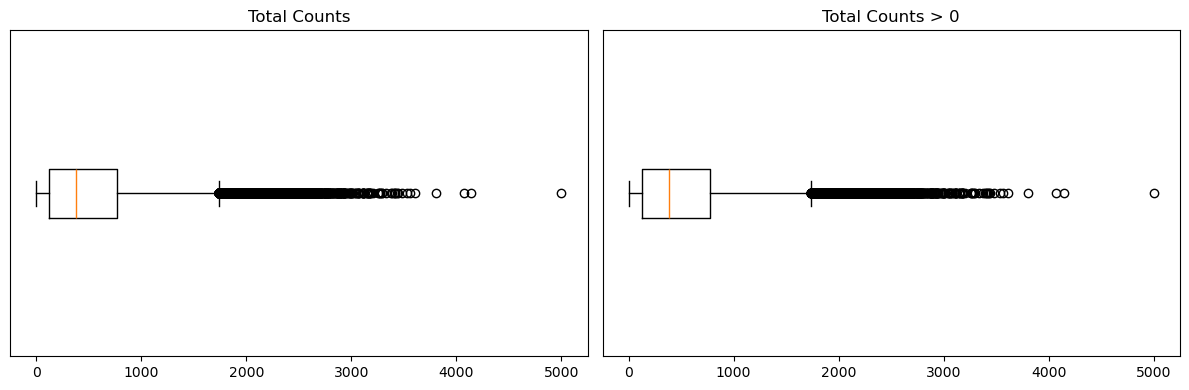

In [8]:
# Plot total UMI distribution (here cutoff = 30. Adapt if necessary)
cutoff=0
plot_cap = 5000 # set if there are massive outliers for better visual plotting.
total_umi(grouped_filtered_adata, cutoff, plot_cap)

In [9]:
# Create a mask based on the 'total_counts' column for values greater than 100
mask_count = grouped_filtered_adata.obs['total_counts'] > cutoff
count_area_filtered_adata = grouped_filtered_adata[mask_count, :]

# Calculate quality control metrics for the filtered AnnData object
sc.pp.calculate_qc_metrics(count_area_filtered_adata, inplace=True)

#del mask_count, adata_filtered_bins

/home/charlottewolf/miniconda3/envs/NucleiSeg/lib/python3.11/site-packages/scanpy/preprocessing/_qc.py:140: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata.obs[obs_metrics.columns] = obs_metrics
/home/charlottewolf/miniconda3/envs/NucleiSeg/lib/python3.11/site-packages/anndata/_core/anndata.py:1820: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


In [10]:
# Normalize total counts for each cell in the AnnData object
sc.pp.normalize_total(count_area_filtered_adata, inplace=True)

# Logarithmize the values in the AnnData object after normalization
sc.pp.log1p(count_area_filtered_adata)

# Identify highly variable genes in the dataset using the Seurat method
sc.pp.highly_variable_genes(count_area_filtered_adata, flavor="seurat", n_top_genes=2000)

# Perform Principal Component Analysis (PCA) on the AnnData object
sc.pp.pca(count_area_filtered_adata)

# Build a neighborhood graph based on PCA components
sc.pp.neighbors(count_area_filtered_adata)

# Perform Leiden clustering on the neighborhood graph and store the results in 'clusters' column

# Adjust the resolution parameter as needed for different samples
resolution = 0.2
sc.tl.leiden(count_area_filtered_adata, resolution=resolution, key_added=f"clusters{resolution}")

#count_area_filtered_adata.write (f"../../Cell_Segmentation/output/{person}/{bin_size}/custom_binning/{super_bin_size}x{super_bin_size}um_count_area_filtered_adata.h5ad")

cluster_count = count_area_filtered_adata.obs[f"clusters{resolution}"].unique().shape[0]
print(f"Found {cluster_count} clusters for leiden resolution {resolution}.")


/home/charlottewolf/miniconda3/envs/NucleiSeg/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
2025-11-25 13:34:19.347676: I tensorflow/core/util/port.cc:113] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2025-11-25 13:34:19.369142: I tensorflow/core/platform/cpu_feature_guard.cc:182] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: SSE4.1 SSE4.2 AVX AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
/tmp/ipykernel_99503/598424583.py:20: FutureWarning: In the future, the default backend

Found 59 clusters for leiden resolution 0.2.


In [12]:
#count_area_filtered_adata = sc.read_h5ad(f"../../Cell_Segmentation/output/{person}/{bin_size}/custom_binning/{super_bin_size}x{super_bin_size}um_test.h5ad")
resolution = 0.01
sc.tl.leiden(count_area_filtered_adata, resolution=resolution, key_added=f"clusters{resolution}")
cluster_count = count_area_filtered_adata.obs[f"clusters{resolution}"].unique().shape[0]
#count_area_filtered_adata.write (f"../../Cell_Segmentation/output/{person}/{bin_size}/custom_binning/{super_bin_size}x{super_bin_size}um_count_area_filtered_adata.h5ad")
print(f"Found {cluster_count} clusters for leiden resolution {resolution}.")

Found 22 clusters for leiden resolution 0.01.


### Run K-Means

In [13]:
#count_area_filtered_adata = sc.read_h5ad(f"../../Cell_Segmentation/output/{person}/{bin_size}/custom_binning/{super_bin_size}x{super_bin_size}um_test.h5ad")
X_pca = count_area_filtered_adata.obsm['X_pca'][:, :20]   # use first 20 PCs, typical choice

k = 7
km = KMeans(n_clusters=k, random_state=0)
count_area_filtered_adata.obs['kmeans'] = km.fit_predict(X_pca)


In [ ]:
# Load if starting from this point
count_area_filtered_adata = sc.read_h5ad(dir_custom_binning / f"output/{sample}/{bin_size}/custom_binning/{super_bin_size}x{super_bin_size}um_count_area_filtered_adata.h5ad")

/home/charlottewolf/miniconda3/envs/NucleiSeg/lib/python3.11/site-packages/anndata/_core/anndata.py:1820: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


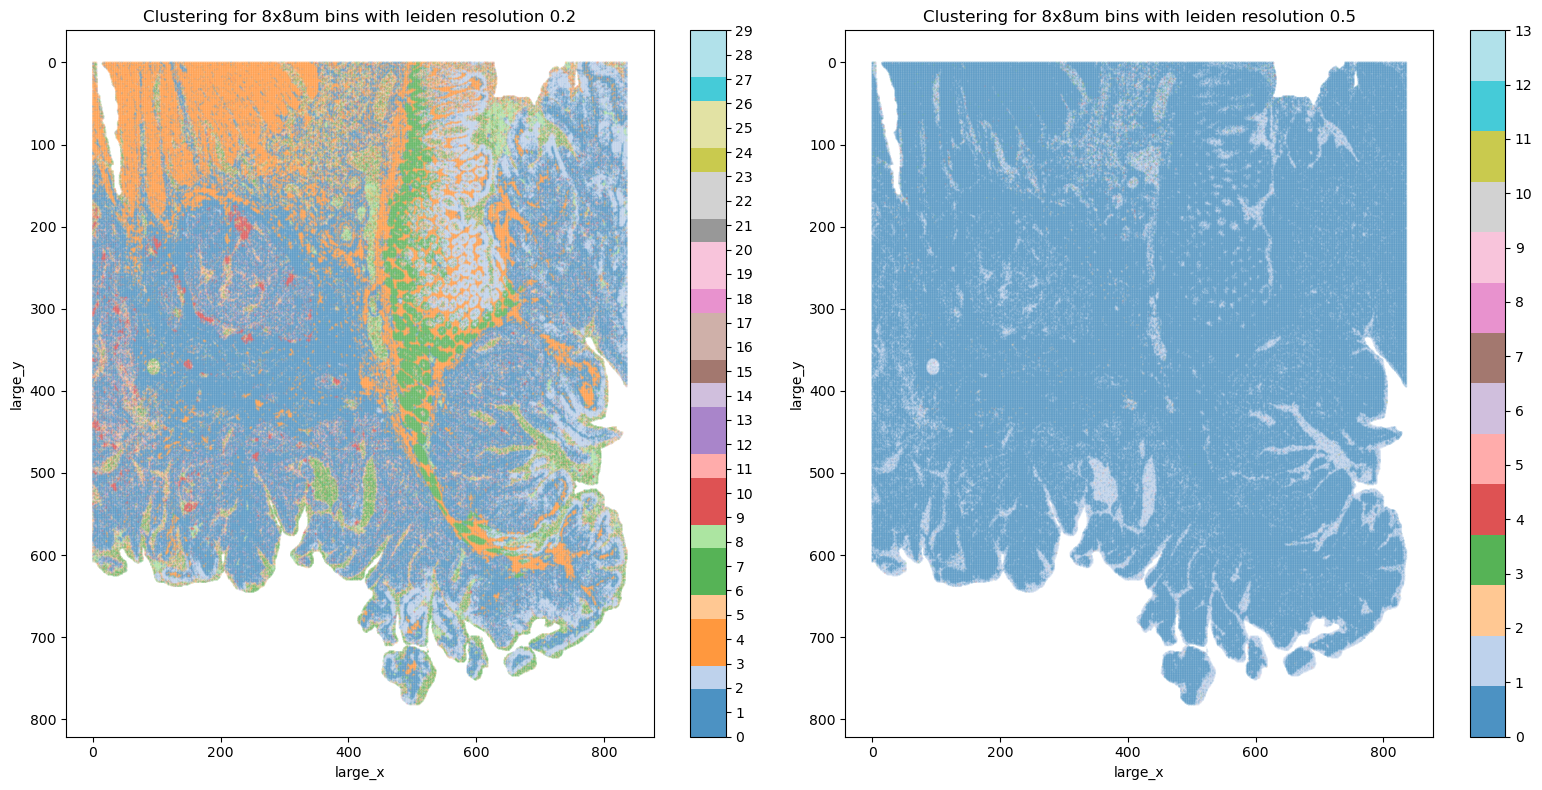

In [26]:
plot1 = "Clustering for 8x8um bins with leiden resolution 0.2"
plot2 = "Clustering for 8x8um bins with leiden resolution 0.5"
plot_bin_clusters_side_by_side(count_area_filtered_adata.obs, 'large_x', 'large_y', plot1, plot2, 'clusters0.2', 'clusters0.02')

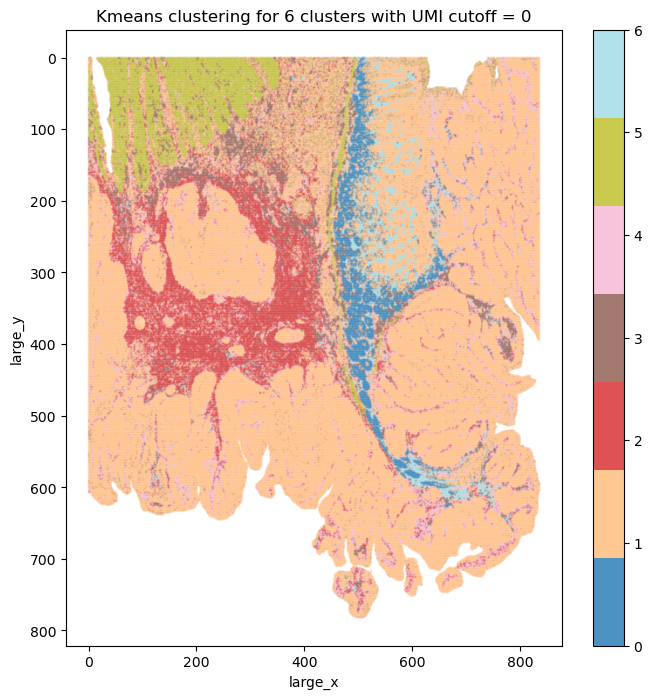

In [14]:
plot_bin_clusters(count_area_filtered_adata.obs, "large_x", "large_y", 'kmeans', "Kmeans clustering for 6 clusters with UMI cutoff = 0")

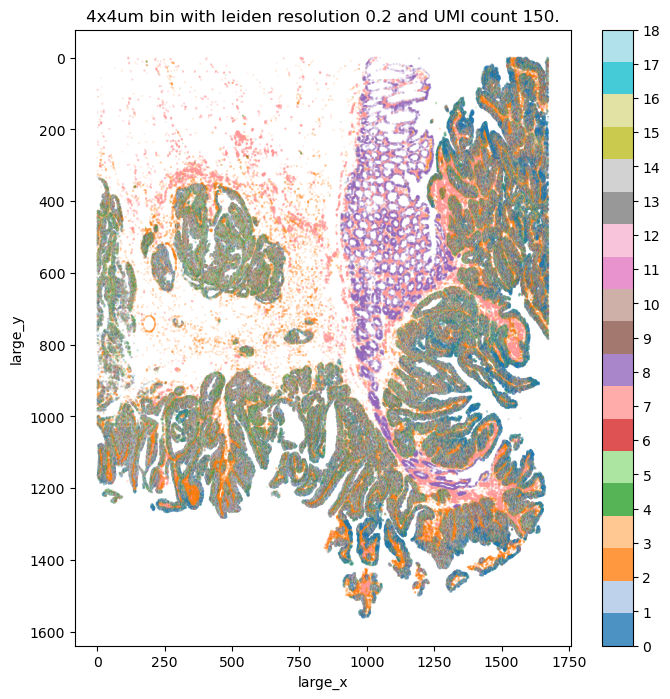

In [18]:
plot_bin_clusters(count_area_filtered_adata.obs, 'large_x', 'large_y', 'clusters', f"4x4um bin with leiden resolution 0.2 and UMI count {cutoff}.")

### For bin size 008um and 016um
Clustering results are already provided by 10x Genomics. 
Hence, we just use the same plotting function, but for larger bins.

In [ ]:
# Variables + paths
bin_size = "008um"
cluster_type = "kmeans_6_clusters" # in spaceranger output: either kmeans or graphclust. Also name of directory
pred_col = "Cluster" # column with predicted cluster info in csv 
dir_base_output = dir_sample / f"output/binned_outputs/square_{bin_size}" # re-assign due to changing bin size

# Get cluster df
pred_cluster_path = dir_base_output / f"analysis/clustering/gene_expression_{cluster_type}/clusters.csv"
pred_df = pd.read_csv(pred_cluster_path, delimiter=',')
pred_df.rename(columns={'Barcode': 'barcode'}, inplace=True)

# Merge cluster annotation with the bin positions
tissue_positions = pd.read_parquet(dir_base_output / "spatial/tissue_positions.parquet")
pred_df = pd.merge(pred_df, tissue_positions, on='barcode', how='left')
del tissue_positions

truth_col = "tissuetype"
truth_df = pd.read_csv((dir_ground_truth / "8um_squares_annotation.csv"), 
                                        delimiter='\t', header=None, names=['barcode', 'tissuetype'])
tissue_positions = pd.read_parquet(dir_base_output / "spatial/tissue_positions.parquet")
truth_df = pd.merge(truth_df, tissue_positions, on='barcode', how='left')

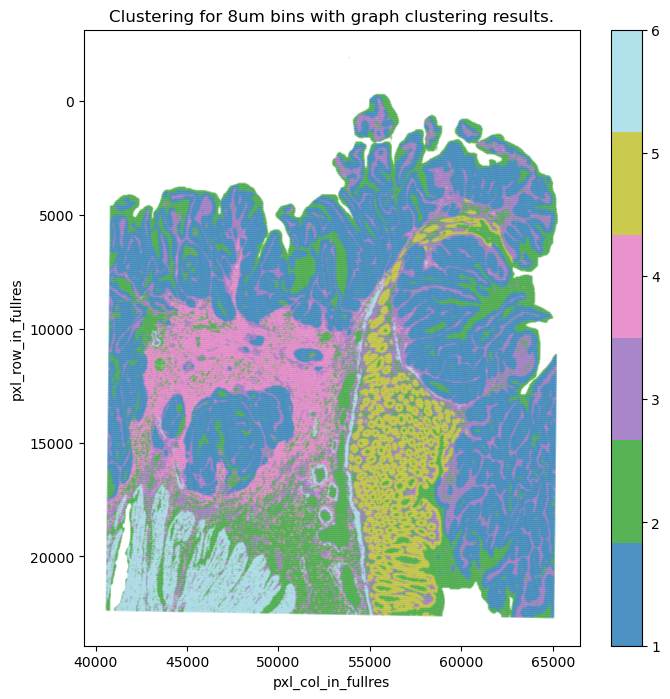

In [13]:
# Plotting the Clusters given in the spaceranger analysis 
plot_bin_clusters(pred_df, 'pxl_col_in_fullres', 'pxl_row_in_fullres', pred_col, "Clustering for 8um bins with graph clustering results.")

In [ ]:
merged_df = pd.merge(truth_df, pred_df, on='barcode', how='left')

get_eval_scores(merged_df, pred_col, truth_col)

Found 63 NaN values in 'Cluster' and 0 in 'tissuetype' out of 545913 rows. Dropping rows ...
Adjusted Rand Index: 0.182
Normalized Mutual Info: 0.361
Homogeneity: 0.548
Completeness: 0.269
V-Measure: 0.361


In [15]:
merged_df = pd.merge(truth_df, pred_df, on='barcode', how='left')
get_eval_scores(merged_df, pred_col, truth_col)

Found 63 NaN values in 'Cluster' and 0 in 'tissuetype' out of 545913 rows. Dropping rows ...
Adjusted Rand Index: 0.401
Normalized Mutual Info: 0.414
Homogeneity: 0.487
Completeness: 0.360
V-Measure: 0.414


### UMAP for 8um

In [ ]:
????

,Barcode,UMAP-1,UMAP-2
0,s_008um_00301_00321-1,6.181511,-5.527058
1,s_008um_00526_00291-1,-8.622928,2.332152
2,s_008um_00078_00444-1,7.390618,0.672600
3,s_008um_00128_00278-1,5.925762,-4.164023
4,s_008um_00052_00559-1,0.242193,2.517896
...,...,...,...
545845,s_008um_00252_00421-1,5.451657,-3.831439
545846,s_008um_00384_00793-1,3.542143,0.220984
545847,s_008um_00565_00244-1,6.575702,-3.412344
545848,s_008um_00353_00477-1,-1.254247,-0.524195


### Clustering for nuclei
After nuclei segmentation, we have bins assigned to nuclei. 
Similar to the results abie, we will now evaluate the clustering results from the preprocessed nuclei/bins.

In [ ]:
# Files
nuclei_info = sc.read_h5ad(dir_custom_binning / "count_area_filtered_adata.h5ad")
# Reads the merged combined/ copy (filtered to this sample, obs only -- .X is never
# touched below) instead of this sample's own per-sample filtered_custom_bins.h5ad,
# so per-sample copies are free to delete once preprocessing is done.
combined_dir_custom_binning = basedir / "combined" / "01_preprocessing" / dir_cellseg / bin_size / "custom_binning"
bin_info_combined = sc.read_h5ad(combined_dir_custom_binning / "filtered_custom_bins.h5ad", backed="r")
bin_obs = bin_info_combined.obs.loc[bin_info_combined.obs["Slide_ID"] == sample].copy()
# Merge prefixes obs_names with "{Slide_ID}_" -- strip it back off so the index
# matches ground_truth's raw (unprefixed) per-sample barcodes below.
bin_obs.index = bin_obs.index.str.removeprefix(sample + "_")
del bin_info_combined
ground_truth = pd.read_csv((dir_ground_truth / "2um_squares_annotation.csv"), delimiter='\t', header=None, names=['barcode', 'ground_truth'])

# copy anndata.obs to separate dataframes
nuclei_obs = nuclei_info.obs.copy()

# Join bins with nucleus info 
merged_obs = bin_obs.join(nuclei_obs[["id", "clusters"]].set_index("id"), on="id", how="inner")
# Join with ground truth
merged_obs = merged_obs.join(ground_truth.set_index("barcode"), how="inner")

merged_obs = merged_obs.drop(columns=["in_tissue", "array_row", "array_col", "index_x", "index_y", "is_within_polygon", 
                                      "is_not_in_an_polygon_overlap", "Slide_ID"]) # readability
merged_obs

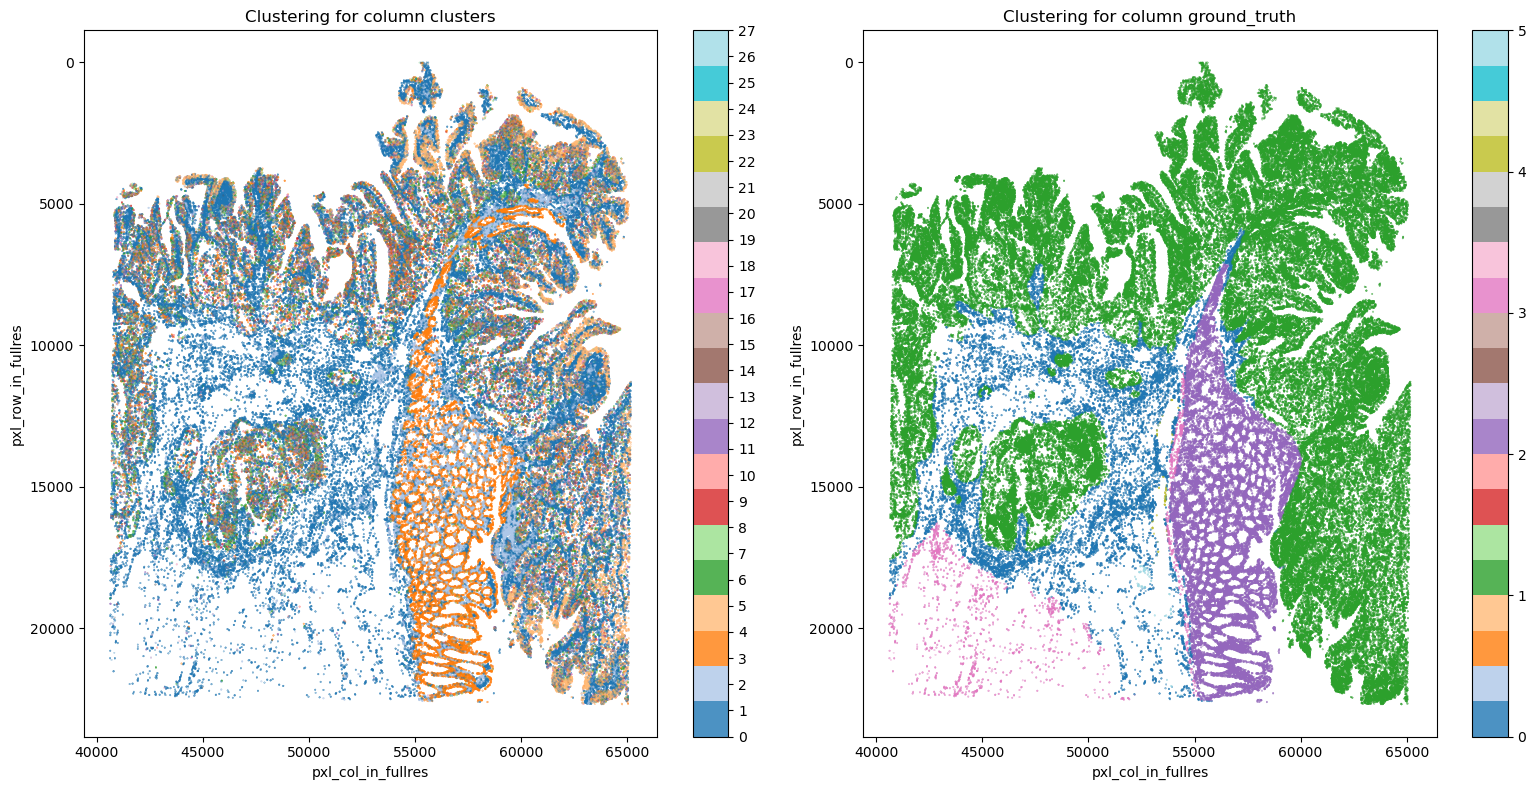

In [12]:
plot_bin_clusters_side_by_side(merged_obs, 'pxl_col_in_fullres', 'pxl_row_in_fullres', "clusters", "ground_truth")

In [13]:
get_eval_scores(merged_obs, "clusters", "ground_truth")

Adjusted Rand Index: -0.004
Normalized Mutual Info: 0.169
Homogeneity: 0.344
Completeness: 0.112
V-Measure: 0.169
